# Wirtinger descent with Adam against Gerchberg-Saxton at equal iterations

**Question:** Does a gradient method that knows nothing about Gerchberg-Saxton, Wirtinger descent with Adam (M11), reach the uniformity of the projection loops on the 10 x 10 trap task at equal iterations?

- Level: 3, state of the art. Method run: M11.
- Prerequisites: `05-optimization/02-the-wirtinger-gradient-and-adams-step`, which derives the gradient and sets the learning rate.
- Reading time: about 25 minutes. The notebook runs in about a minute and a half.

## Objectives

A level 3 notebook runs a method of the state of the art on the product's data and measures it against what came before. M11 comes from machine-learning holography (Chakravarthula et al., 2019): its attraction is that it needs no rule written for the problem, only a differentiable model and a loss. The price is paid in iterations, and this notebook counts them. By the end you can:

- compare M11 with plain and weighted Gerchberg-Saxton on three seeds at the registry's budget of 30 iterations;
- say what the spread of the three seeds tells about each method;
- follow the three methods to 100 iterations and read both the curves and the final trap intensities;
- say which claim of the method ladder the numbers support, and which they do not.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m06_gsw
from pipeline.model.holo.methods.optim import m11_wirtinger_adam

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C12 of `data/examples/cases.json`, the same 10 x 10 calibration task as the previous notebook.

- Owner: this repository; the case is synthetic and follows the task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12.

In [2]:
# case C12: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
n = setup.n_pix
print(rec["case_id"], "|", len(target.traps), "traps | SLM", n, "x", n, "pixels")

C12_calibration | 100 traps | SLM 256 x 256 pixels


## Method

M11 minimises the quadratic loss $C_2$ of the optimisation topic by Adam on the Wirtinger gradient, with the learning rate 1.0 tuned in the previous notebook, starting from random phases drawn through the seeded generator. It has no weights, no phase fixing and no projection. The two methods it is compared with are the classical loops of Di Leonardo et al. (2007): M04, plain Gerchberg-Saxton, which replaces the amplitude in the focal plane by the target and has no mechanism that evens out the traps, and M06, the weighted loop, which multiplies the target of each trap by a weight that corrects its deficit. The method ladder asks M11 for a lower trap-intensity error than M04 at equal iterations, so M04 is the contract; M06 is the strongest classical opponent.

## State of the art

No pinned reference implementation of M11 exists among the notebook dependencies (slmsuite offers the Gerchberg-Saxton family, not gradient descent through a differentiable model), so the state of the art is run as DinHot's own M11 against its own classical loops on the same task, the same three seeds and the same budget. The first cell runs M04 for 30 iterations on three seeds.

In [3]:
# plain Gerchberg-Saxton, M04, 30 iterations on three seeds
spread = {"M04 GS": [], "M06 GSW": [], "M11 Adam": []}
for seed in (1, 2, 3):
    spread["M04 GS"].append(m04_gs.run(setup, target, budget=Budget(30), rng=Rng(seed)).history[-1]["rel_std"])
print(f"M04: rel. std per seed {np.round(spread['M04 GS'], 2)} %  mean {np.mean(spread['M04 GS']):.2f} %")

M04: rel. std per seed [17.28 18.38 18.76] %  mean 18.14 %


Plain Gerchberg-Saxton leaves the traps 17.28 to 18.76 percent apart. The weighted loop M06 is the classical answer to that, and the second cell runs it on the same seeds.

In [4]:
# weighted GS, M06, the classical reference, with the same budget and seeds
for seed in (1, 2, 3):
    spread["M06 GSW"].append(m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(seed)).history[-1]["rel_std"])
print(f"M06: rel. std per seed {np.round(spread['M06 GSW'], 2)} %  mean {np.mean(spread['M06 GSW']):.2f} %")

M06: rel. std per seed [1.36 0.64 1.32] %  mean 1.11 %


M06 is at 1.36, 0.64 and 1.32 percent. The third cell runs M11 with the same budget and seeds.

In [5]:
# Wirtinger-Adam, M11, learning rate 1.0, the same budget and seeds
for seed in (1, 2, 3):
    res = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(seed))
    spread["M11 Adam"].append(res.history[-1]["rel_std"])
print(f"M11: rel. std per seed {np.round(spread['M11 Adam'], 2)} %  mean {np.mean(spread['M11 Adam']):.2f} %")

M11: rel. std per seed [2.56 2.66 2.22] %  mean 2.48 %


The bars plot the relative standard deviation of each method on each seed, on a log axis.

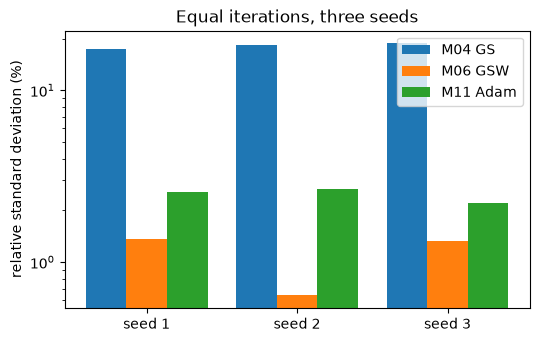

In [6]:
# relative standard deviation of the three methods on each seed, 30 iterations
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for k, (name, values) in enumerate(spread.items()):
    ax.bar(np.arange(3) + 0.27 * (k - 1), values, 0.27, label=name)
ax.set_xticks(range(3))
ax.set_xticklabels(["seed 1", "seed 2", "seed 3"])
ax.set_ylabel("relative standard deviation (%)")
ax.set_title("Equal iterations, three seeds")
ax.set_yscale("log")
ax.legend()
plt.show()

M11 beats plain Gerchberg-Saxton on every seed, with a mean of 2.48 percent against 18.14, a factor of 7 that is the same on all three, so the criterion of the method ladder holds and does not depend on the seed. It does not beat the weighted loop, whose mean is 1.11 percent. The seeds also show a difference in character: M06 ranges from 0.64 to 1.36 percent, a factor of 2.1, because its weight update has the sensitivity to the start that the path of an adaptive loop has, while M11 ranges only from 2.22 to 2.66, a factor of 1.2, since a descent on a smooth cost forgets its start sooner. The figure is for 30 iterations; the cells below follow the three methods further.

Thirty iterations is the registry's default, but a descent method is judged also by where it goes with more. The next three cells run the three methods for 100 iterations on seed 1, and keep the final field so that the intensity of each trap can be compared. M04 first.

In [7]:
# the same three methods for 100 iterations on seed 1: M04 first
long = {"M04 GS": m04_gs.run(setup, target, budget=Budget(100), rng=Rng(1))}
h30, h100 = long["M04 GS"].history[29], long["M04 GS"].history[99]
print(f"M04: rel. std at 30 and 100 iterations {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"efficiency {h100['efficiency']:.3f}")

M04: rel. std at 30 and 100 iterations 17.28 % 16.46 %  efficiency 0.819


M04 has stalled: its spread is 17.28 percent at 30 iterations and 16.46 at 100. Then M06.

In [8]:
# then M06
long["M06 GSW"] = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
h30, h100 = long["M06 GSW"].history[29], long["M06 GSW"].history[99]
print(f"M06: rel. std at 30 and 100 iterations {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"efficiency {h100['efficiency']:.3f}")

M06: rel. std at 30 and 100 iterations 1.36 % 0.56 %  efficiency 0.807


M06 goes from 1.36 to 0.56 percent. And M11.

In [9]:
# and M11
long["M11 Adam"] = m11_wirtinger_adam.run(setup, target, budget=Budget(100), rng=Rng(1))
h30, h100 = long["M11 Adam"].history[29], long["M11 Adam"].history[99]
print(f"M11: rel. std at 30 and 100 iterations {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"efficiency {h100['efficiency']:.3f}")

M11: rel. std at 30 and 100 iterations 2.56 % 1.15 %  efficiency 0.808


The left panel plots the spread against the iteration and the right panel the sorted trap intensities.

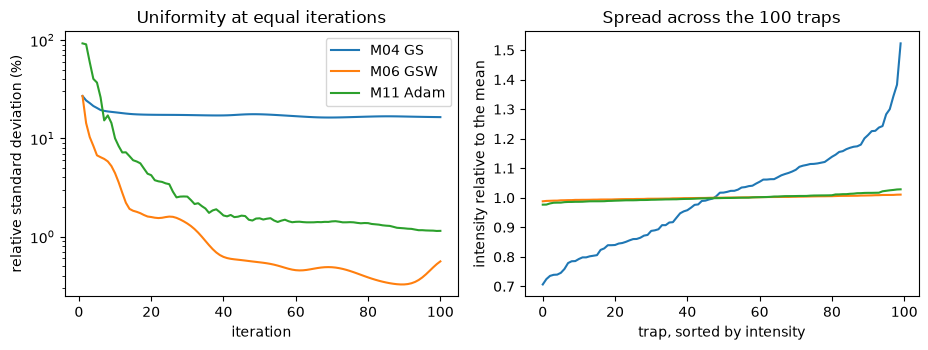

In [10]:
# left: relative spread against iteration; right: sorted trap intensities after 100 iterations
fig, (a, b) = plt.subplots(1, 2, figsize=(9.4, 3.6))
for name, res in long.items():
    a.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=name)
    inten = np.abs(res.fields) ** 2
    b.plot(np.sort(inten / inten.mean()), label=name)
a.set_xlabel("iteration")
a.set_ylabel("relative standard deviation (%)")
a.set_title("Uniformity at equal iterations")
a.legend()
b.set_xlabel("trap, sorted by intensity")
b.set_ylabel("intensity relative to the mean")
b.set_title("Spread across the 100 traps")
plt.tight_layout()
plt.show()

On the left, plain Gerchberg-Saxton stalls near 17 percent: it has no mechanism that evens out the traps, and its fixed point is uneven by construction. M11 falls steadily and, by 100 iterations, is at 1.15 percent; the weighted loop M06 is below M11 at every iteration, reaches about 0.33 percent near iteration 90 and ends at 0.56 percent after a late rise, the bumps of its weight update. On the right, the sorted intensities say where the spread lives. M04 has a long tail of strong traps, the strongest at about 1.5 times the mean and the weakest at about 0.7; M11 spans about 0.975 to 1.03 of the mean and M06 is flat. The figure supports a narrow statement: a gradient through the forward model beats an unweighted projection and approaches a weighted one, with no weights, and with no knowledge of Gerchberg-Saxton at all. It does not show M11 beating M06, which it does not.

## Results

**Answer:** M11 reaches the uniformity of the projection loops only in part. At equal iterations it beats plain Gerchberg-Saxton on every seed, with a mean relative standard deviation of 2.48 percent against 18.14 for M04 at 30 iterations, and it is at 1.15 percent after 100 iterations against 16.46 for M04. It does not match the weighted loop, which has a mean of 1.11 percent at 30 iterations and is at 0.56 percent after 100, with M11 spread over a narrower range across seeds (2.22 to 2.66 percent against 0.64 to 1.36). So the acceptance criterion of the method ladder holds and M11 is a state-of-the-art method that needs no rule written for the problem, but on a plain point-trap task the classical weighted loop is the better tool.

What the notebook does not show is an independent implementation of M11, which does not exist among the dependencies, or the targets where no weight rule exists and the generality is the point.

## Summary

- M11 beats plain Gerchberg-Saxton on every seed at 30 iterations, by a factor of 7 on the mean spread.
- The weighted loop M06 is still ahead on this task at 30 and at 100 iterations.
- M11 varies less across seeds than M06 does.
- No pinned reference implementation of M11 exists among the dependencies, so the state of the art is DinHot's own method against its own classical loops.

## References

- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Kingma and Ba (2015). Adam: a method for stochastic optimization. https://arxiv.org/abs/1412.6980